# 🌿 Plant Disease Detection with Deep Learning

Detects **38 plant leaf conditions** (healthy + diseased) from a photo using **transfer learning (MobileNetV2)** on the PlantVillage dataset (54,305 images), then launches a **Gradio web app** where you can upload a leaf photo.

**Before you start:** `Runtime → Change runtime type → T4 GPU`, then run the cells top to bottom (`Runtime → Run all`).

**Pipeline:** Download data → Explore → Build model → Train (2 phases) → Evaluate → Save to Drive → Live demo

⏱️ Total time on a free T4 GPU: roughly 20–30 minutes (the first step downloads ~1 GB of images from GitHub).

## 1. Setup

In [1]:
!pip install -q gradio

import os, json, random, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPU found:", gpus if gpus else "NO GPU -> go to Runtime > Change runtime type > T4 GPU")

TensorFlow: 2.21.0
GPU found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Mount Google Drive (the trained model will be saved here)
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/plant_disease_project'
os.makedirs(SAVE_DIR, exist_ok=True)
print("Model will be saved in:", SAVE_DIR)

Mounted at /content/drive
Model will be saved in: /content/drive/MyDrive/plant_disease_project


In [3]:
# ---- Settings (change these if you like) ----
IMG_SIZE    = 160    # image size fed to the model
BATCH_SIZE  = 64
EPOCHS_HEAD = 3      # phase 1: train only the new classification layer
EPOCHS_FINE = 3      # phase 2: fine-tune the top of MobileNetV2
SEED        = 42
MAX_IMAGES  = None   # set e.g. 8000 for a quick test run; None = use all 54,305 images

tf.keras.utils.set_random_seed(SEED)

## 2. Download the PlantVillage dataset

The images are downloaded from the public GitHub copy of PlantVillage (~1 GB, takes 1–3 minutes). Only the colour images are fetched.

In [4]:
REPO_DIR = '/content/PlantVillage-Dataset'
DATA_DIR = os.path.join(REPO_DIR, 'raw', 'color')

if not os.path.isdir(DATA_DIR) or len(os.listdir(DATA_DIR)) < 38:
    subprocess.run(['rm', '-rf', REPO_DIR])
    subprocess.run(['git', 'clone', '--depth', '1', '--filter=blob:none', '--sparse',
                    'https://github.com/spMohanty/PlantVillage-Dataset.git', REPO_DIR], check=True)
    subprocess.run(['git', '-C', REPO_DIR, 'sparse-checkout', 'set', 'raw/color'], check=True)

class_names = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
NUM_CLASSES = len(class_names)

def pretty(name):
    return name.replace('___', ' — ').replace('_', ' ').strip()

print(f"Dataset ready ✅  Classes found: {NUM_CLASSES}")

Dataset ready ✅  Classes found: 38


## 3. Split into train (80%) / validation (10%) / test (10%)

In [5]:
paths, labels = [], []
for idx, cname in enumerate(class_names):
    folder = os.path.join(DATA_DIR, cname)
    for fname in sorted(os.listdir(folder)):
        if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            paths.append(os.path.join(folder, fname))
            labels.append(idx)

paths, labels = np.array(paths), np.array(labels, dtype=np.int32)

if MAX_IMAGES:   # quick-test mode
    keep = np.random.RandomState(SEED).permutation(len(paths))[:MAX_IMAGES]
    paths, labels = paths[keep], labels[keep]

# stratified split keeps the same class proportions in every part
tr_p, tmp_p, tr_l, tmp_l = train_test_split(paths, labels, test_size=0.20, stratify=labels, random_state=SEED)
va_p, te_p, va_l, te_l   = train_test_split(tmp_p, tmp_l, test_size=0.50, stratify=tmp_l, random_state=SEED)

print(f"Total: {len(paths)} images")
print(f"Train: {len(tr_p)} | Validation: {len(va_p)} | Test: {len(te_p)}")

Total: 54305 images
Train: 43444 | Validation: 5430 | Test: 5431


## 4. Look at the data

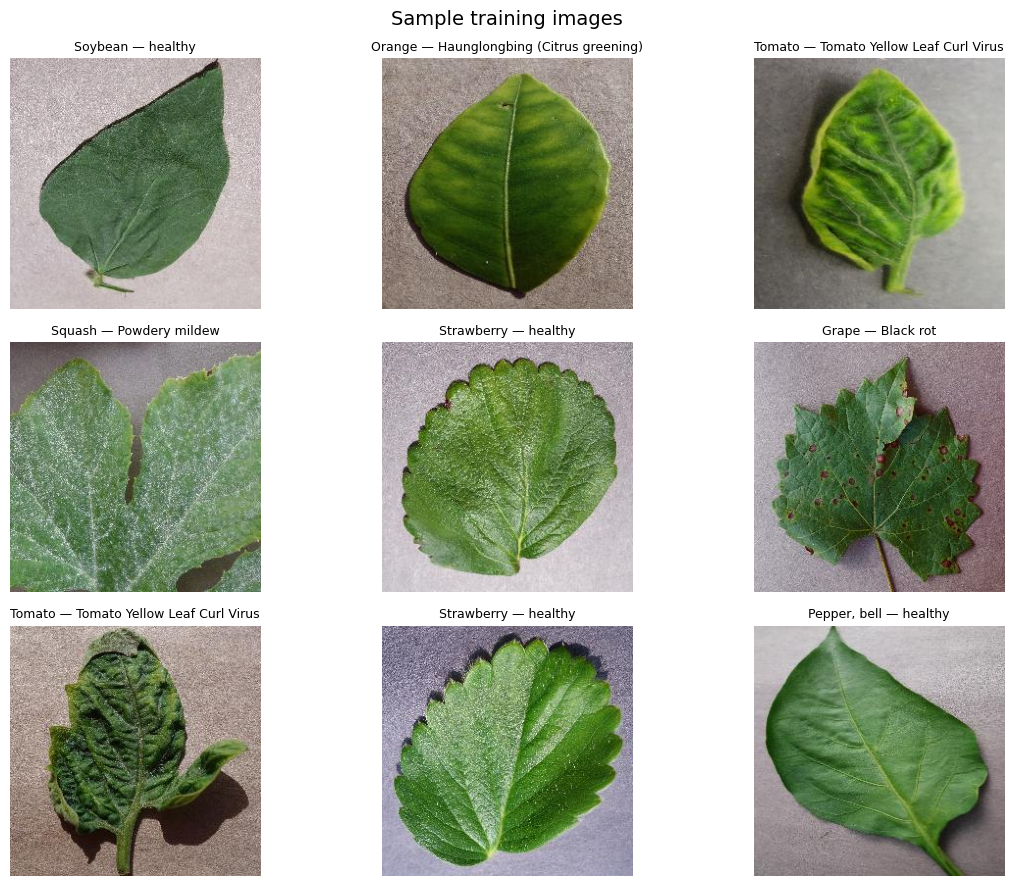

In [6]:
from PIL import Image

plt.figure(figsize=(12, 9))
for i, j in enumerate(np.random.RandomState(1).choice(len(tr_p), 9, replace=False)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(Image.open(tr_p[j]).convert('RGB'))
    plt.title(pretty(class_names[tr_l[j]]), fontsize=9)
    plt.axis('off')
plt.suptitle("Sample training images", fontsize=14)
plt.tight_layout()
plt.show()

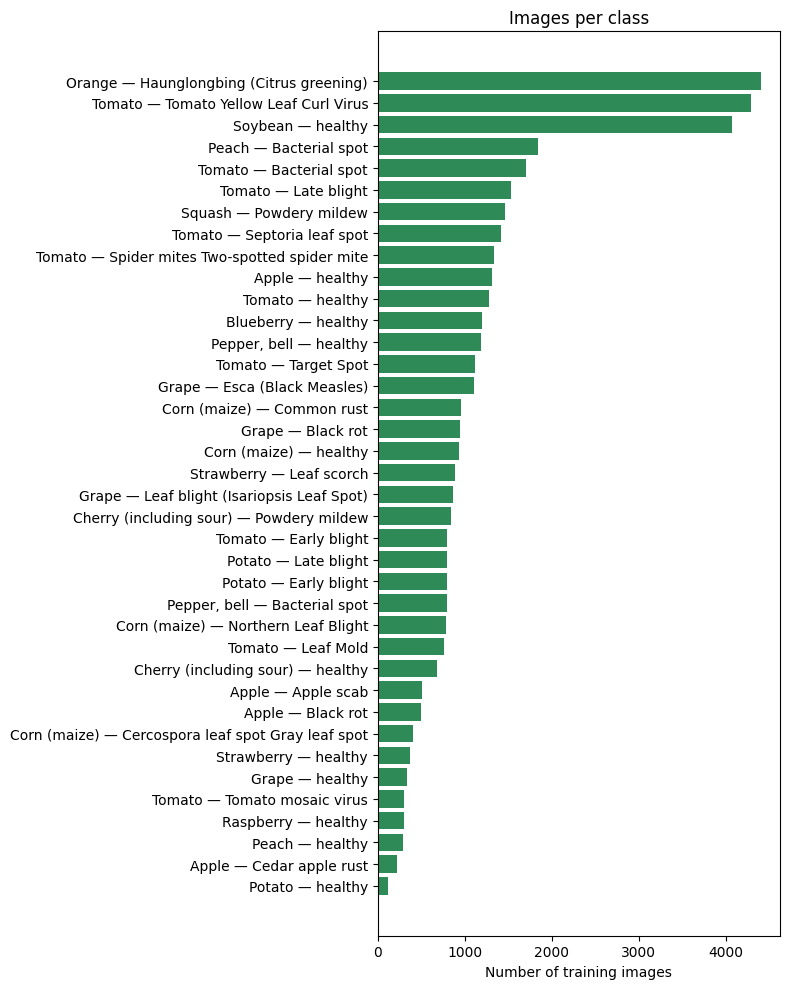

In [7]:
# How many images per class? (shows class imbalance)
counts = np.bincount(tr_l, minlength=NUM_CLASSES)
df_counts = pd.DataFrame({'Class': [pretty(c) for c in class_names], 'Images': counts}).sort_values('Images')
plt.figure(figsize=(8, 10))
plt.barh(df_counts['Class'], df_counts['Images'], color='seagreen')
plt.xlabel('Number of training images')
plt.title('Images per class')
plt.tight_layout()
plt.show()

## 5. Build the input pipeline

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(img, tf.float32), label

def make_ds(p, l, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, l))
    if training:
        ds = ds.shuffle(len(p), seed=SEED)
    return ds.map(load_image, AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(tr_p, tr_l, training=True)
val_ds   = make_ds(va_p, va_l)
test_ds  = make_ds(te_p, te_l)
print("Pipeline ready ✅")

Pipeline ready ✅


## 6. Build the model (MobileNetV2 + new classification head)

MobileNetV2 is pre-trained on ImageNet, so it already knows edges, textures and shapes. We only teach it leaf diseases on top. Data augmentation (flip, rotate, zoom, contrast) makes it robust to real-world photos.

In [9]:
augment = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name='augmentation')

base_model = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base_model.trainable = False   # phase 1: keep the pre-trained part frozen

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augment(inputs)
x = layers.Rescaling(1/127.5, offset=-1)(x)       # scale pixels to [-1, 1] for MobileNetV2
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 7. Train — Phase 1 (train only the new head)

In [10]:
early_stop = keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=2, restore_best_weights=True)

history1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=[early_stop])

Epoch 1/3
679/679 ━━━━━━━━━━━━━━━━━━━━ 61s 73ms/step - accuracy: 0.8065 - loss: 0.6800 - val_accuracy: 0.8983 - val_loss: 0.3436
Epoch 2/3
679/679 ━━━━━━━━━━━━━━━━━━━━ 54s 79ms/step - accuracy: 0.9017 - loss: 0.3098 - val_accuracy: 0.9094 - val_loss: 0.2956
Epoch 3/3
679/679 ━━━━━━━━━━━━━━━━━━━━ 49s 72ms/step - accuracy: 0.9130 - loss: 0.2653 - val_accuracy: 0.9127 - val_loss: 0.2701


## 8. Train — Phase 2 (fine-tune the top layers of MobileNetV2)

In [11]:
base_model.trainable = True
for layer in base_model.layers[:-30]:      # keep early layers frozen
    layer.trainable = False
for layer in base_model.layers:            # keep BatchNorm layers frozen for stable fine-tuning
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),   # much smaller learning rate
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

early_stop = keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=2, restore_best_weights=True)
history2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE, callbacks=[early_stop])

Epoch 1/3
679/679 ━━━━━━━━━━━━━━━━━━━━ 65s 85ms/step - accuracy: 0.9316 - loss: 0.2097 - val_accuracy: 0.9278 - val_loss: 0.2245
Epoch 2/3
679/679 ━━━━━━━━━━━━━━━━━━━━ 55s 82ms/step - accuracy: 0.9417 - loss: 0.1753 - val_accuracy: 0.9319 - val_loss: 0.2091
Epoch 3/3
679/679 ━━━━━━━━━━━━━━━━━━━━ 83s 83ms/step - accuracy: 0.9454 - loss: 0.1601 - val_accuracy: 0.9440 - val_loss: 0.1740


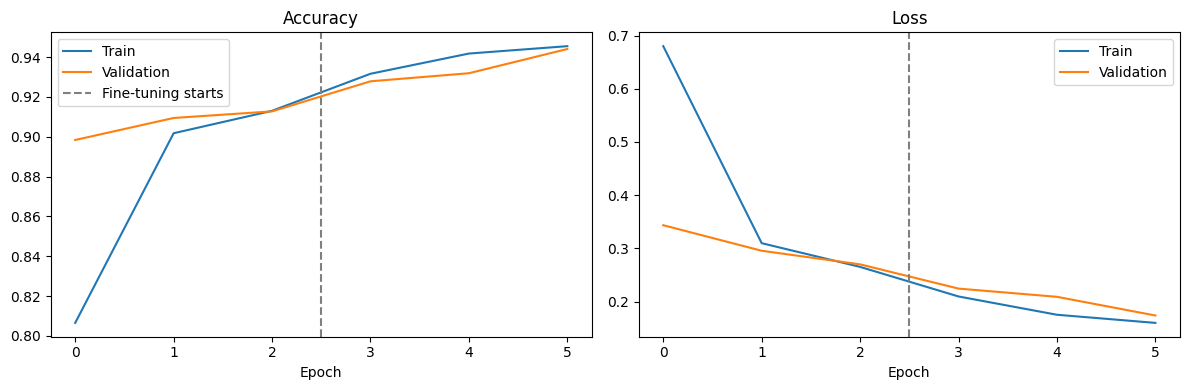

In [12]:
# Training curves (both phases joined together)
acc     = history1.history['accuracy']     + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss    = history1.history['loss']         + history2.history['loss']
val_loss= history1.history['val_loss']     + history2.history['val_loss']
switch  = len(history1.history['accuracy']) - 0.5

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(acc, label='Train'); ax[0].plot(val_acc, label='Validation')
ax[0].axvline(switch, color='gray', ls='--', label='Fine-tuning starts')
ax[0].set_title('Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot(loss, label='Train'); ax[1].plot(val_loss, label='Validation')
ax[1].axvline(switch, color='gray', ls='--')
ax[1].set_title('Loss'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout()
plt.show()

## 9. Evaluate on the test set (images the model has never seen)

In [13]:
y_true, y_pred = [], []
first_images = None
for images, lbls in test_ds:
    probs = model.predict(images, verbose=0)
    y_true.extend(lbls.numpy())
    y_pred.extend(np.argmax(probs, axis=1))
    if first_images is None:
        first_images, first_labels, first_preds = images.numpy(), lbls.numpy(), np.argmax(probs, axis=1)

y_true, y_pred = np.array(y_true), np.array(y_pred)
test_acc = (y_true == y_pred).mean()
print(f"✅ The model identifies the correct plant condition in {test_acc*100:.2f}% of unseen test images")
print(f"   ({(y_true == y_pred).sum()} correct out of {len(y_true)})")

✅ The model identifies the correct plant condition in 94.24% of unseen test images
   (5118 correct out of 5431)


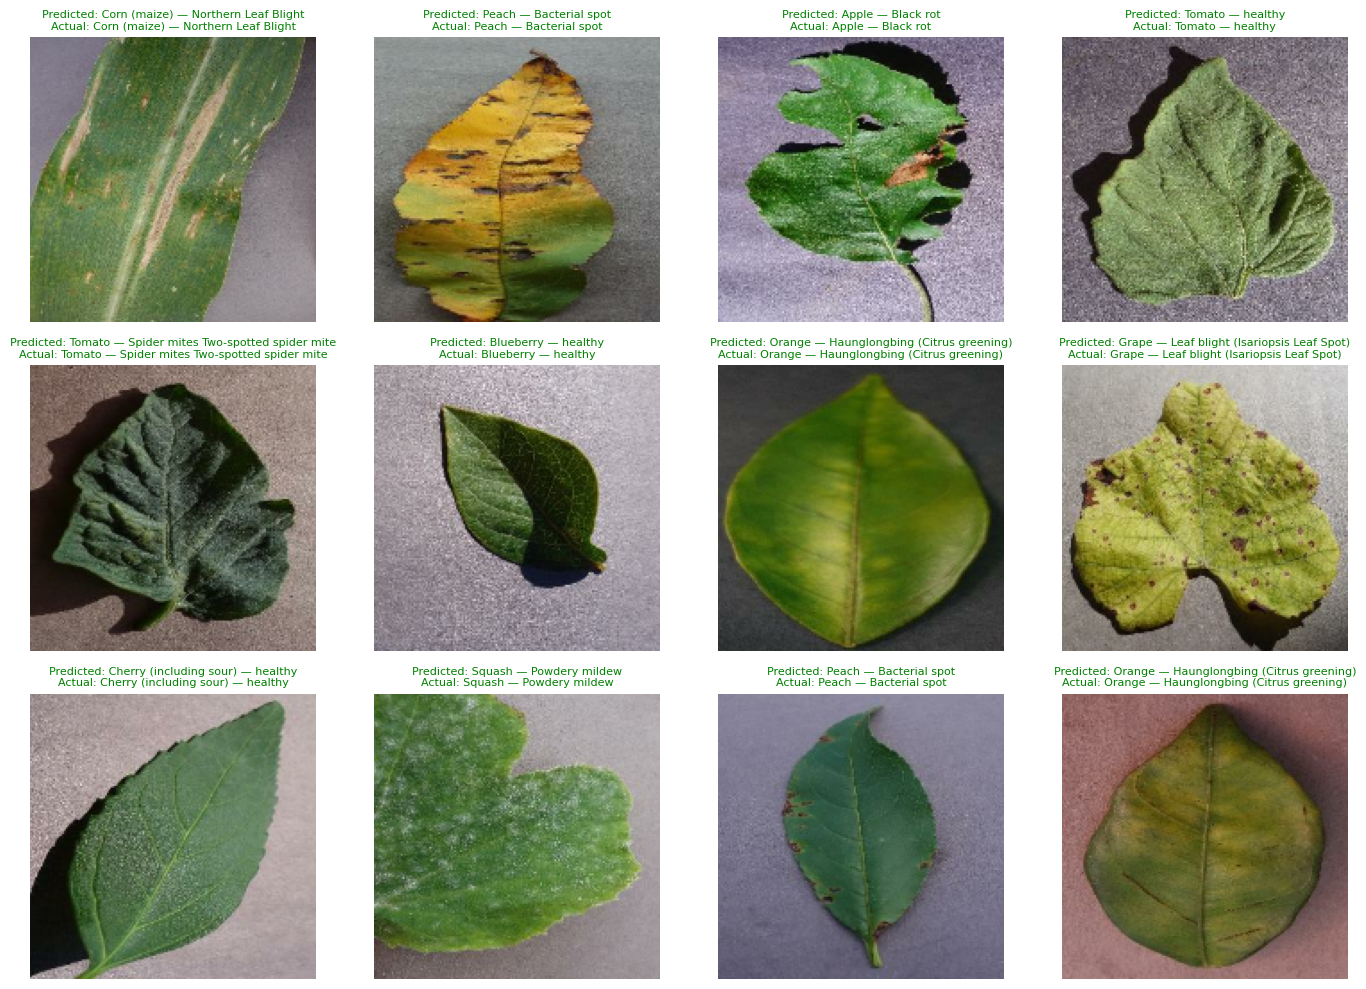

In [14]:
# Sample predictions: green = correct, red = wrong
idx = np.random.choice(len(first_images), min(12, len(first_images)), replace=False)
plt.figure(figsize=(14, 10))
for i, j in enumerate(idx):
    plt.subplot(3, 4, i + 1)
    plt.imshow(first_images[j].astype('uint8'))
    ok = first_preds[j] == first_labels[j]
    plt.title(f"Predicted: {pretty(class_names[first_preds[j]])}\nActual: {pretty(class_names[first_labels[j]])}",
              color='green' if ok else 'red', fontsize=8)
    plt.axis('off')
plt.tight_layout()
plt.show()

In [15]:
# Which classes are hardest for the model?
rows = []
for c in range(NUM_CLASSES):
    mask = y_true == c
    if mask.sum() > 0:
        rows.append((pretty(class_names[c]), int(mask.sum()), round((y_pred[mask] == c).mean() * 100, 1)))
per_class = pd.DataFrame(rows, columns=['Plant condition', 'Test images', 'Accuracy (%)']).sort_values('Accuracy (%)')
print("5 hardest classes:")
display(per_class.head(5).reset_index(drop=True))

5 hardest classes:


,Plant condition,Test images,Accuracy (%)
0,Potato — healthy,15,53.3
1,Tomato — Early blight,100,57.0
2,Corn (maize) — Cercospora leaf spot Gray leaf ...,51,70.6
3,Tomato — Tomato mosaic virus,37,73.0
4,Tomato — Late blight,191,74.9


> **Note on the score:** PlantVillage contains several photos of each physical leaf, so near-identical photos can end up in both the train and test parts. That makes the accuracy above higher than what you'd get on brand-new leaves or on real field photos. Mention this honestly in your report — it shows good judgement.

## 10. Save the model to Google Drive

In [16]:
model.save(os.path.join(SAVE_DIR, 'plant_disease_model.keras'))
with open(os.path.join(SAVE_DIR, 'class_names.json'), 'w') as f:
    json.dump(class_names, f)
print("Saved to:", SAVE_DIR)
print(os.listdir(SAVE_DIR))

Saved to: /content/drive/MyDrive/plant_disease_project
['plant_disease_model.keras', 'class_names.json']


## 11. Live demo — upload a leaf photo 🍃

In [17]:
import gradio as gr

def predict_leaf(img):
    if img is None:
        return None
    img = img.convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    arr = np.expand_dims(np.array(img, dtype='float32'), 0)
    probs = model.predict(arr, verbose=0)[0]
    return {pretty(class_names[i]): float(probs[i]) for i in range(NUM_CLASSES)}

demo = gr.Interface(
    fn=predict_leaf,
    inputs=gr.Image(type='pil', label='Upload a leaf photo'),
    outputs=gr.Label(num_top_classes=3, label='Prediction'),
    title='🌿 Plant Disease Detector',
    description='Upload a clear photo of a single leaf. Works for 38 plant conditions (apple, corn, grape, potato, tomato and more).',
)
demo.launch(share=True)   # opens a public link valid for 72 hours

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6648dba5bcf91919d6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## ✅ Done! Ideas to extend this project

- Test the app with a real leaf photo (the model is trained on clean, single-leaf images on plain backgrounds)
- Try `EfficientNetB0` or `ResNet50` instead of MobileNetV2 and compare accuracy and speed
- Add **Grad-CAM** heatmaps to show *where* the model looks on the leaf
- Convert to **TensorFlow Lite** for a mobile app
- Add a treatment-advice table that maps each disease to a recommended action